In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('sar_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

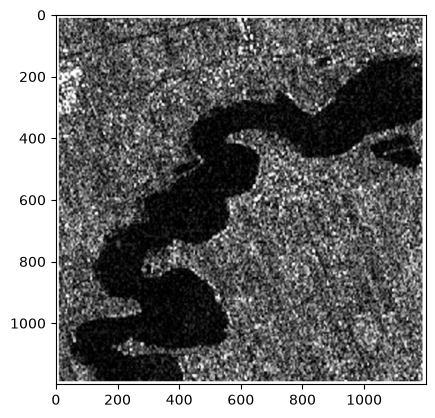

In [3]:
plt.imshow(image_gray, cmap="gray")

# Точечная бинаризация

In [4]:
import copy

bin_img = copy.deepcopy(image_gray)
T  = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

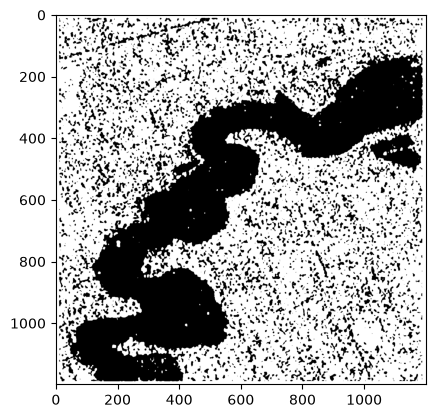

In [5]:
plt.imshow(bin_img, cmap="gray")

# Бинаризация Отсу

In [6]:
# otsu binarization
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

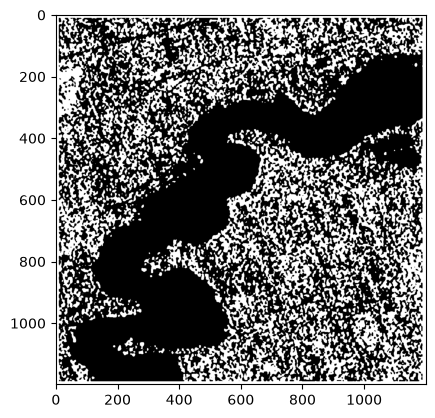

In [7]:
plt.imshow(th2, cmap="gray")

# Адаптивная бинаризация

In [8]:
# 
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)


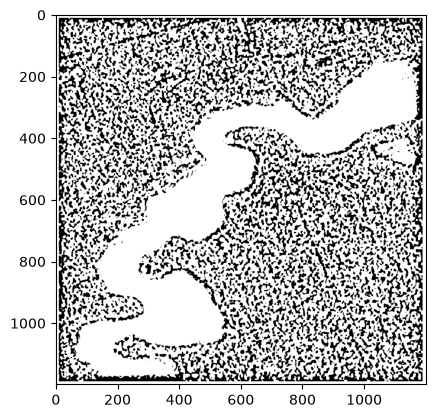

In [9]:
plt.imshow(th3, cmap="gray")

# Оператор Собеля

In [10]:
scale = 1
delta = 0
ddepth = cv2.CV_16S
grad_x = cv2.Sobel(image_gray, ddepth, 1, 0, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad_y = cv2.Sobel(image_gray, ddepth, 0, 1, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)

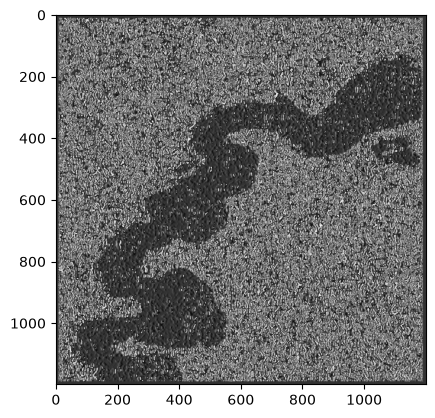

In [11]:
plt.imshow((grad_x - grad_x.min())*255, cmap="gray")

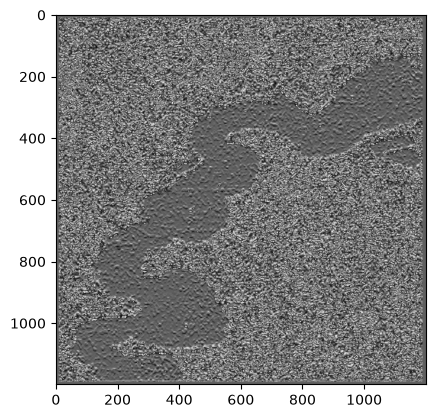

In [12]:
plt.imshow((grad_y - grad_y.min())*255, cmap="gray")

In [13]:
grad = cv2.addWeighted(grad_x, 0.5, grad_y, 0.5,0.0) # mean value between

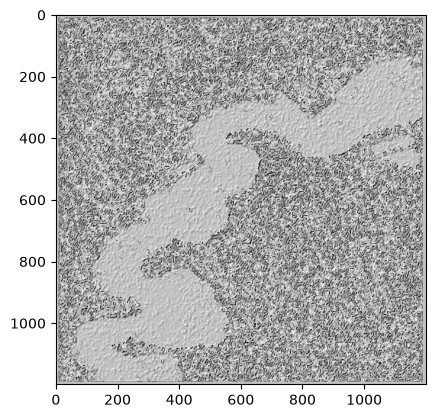

In [14]:
plt.imshow((grad - grad.min())*255, cmap="gray")

# Canny

In [15]:
edges = cv2.Canny(image_gray,100,200)

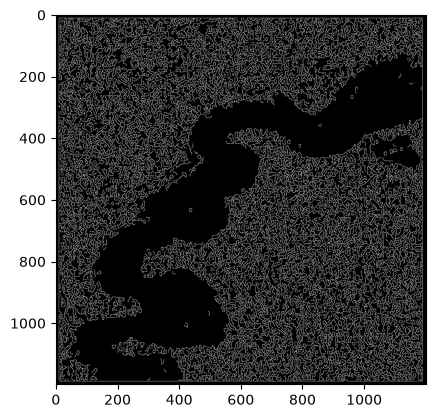

In [16]:
plt.imshow(edges, cmap="gray")

# Преобразование Хафа

In [17]:
image = cv2.imread('img_1.jpg')
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) 
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

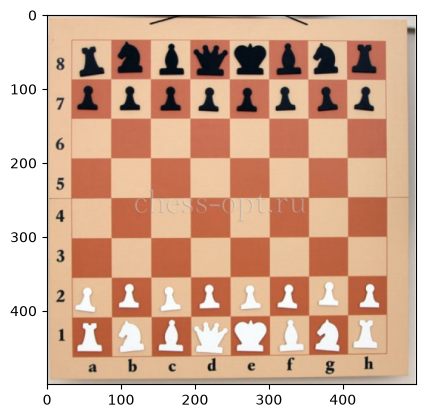

In [18]:
plt.imshow(image)

In [19]:
canny = cv2.Canny(image_gray,50,150,apertureSize = 3)

In [20]:
lines = cv2.HoughLines(canny, 1, np.pi / 180, 190)

In [21]:
import math 

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            a = math.cos(theta)
            b = math.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(image, pt1, pt2, (0,0,255), 3, cv2.LINE_AA)

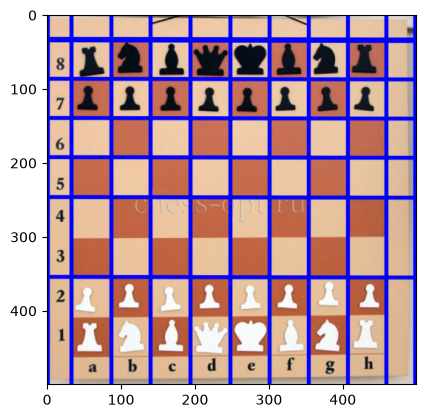

In [22]:
plt.imshow(image)

# Домашнее задание

**Задачи:**
1. Для изображения `sar_3.jpg` найти наиболее протяженный участок (выделить линии при помощи преобразования Хафа).
2. Для изображения `sar_3.jpg` провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

## Задание 1. Поиск наиболее протяженного участка (Хаф)

Найдено линий: 99
Самый длинный участок: от (35, 221) до (224, 79)
Длина участка: 236.4 px


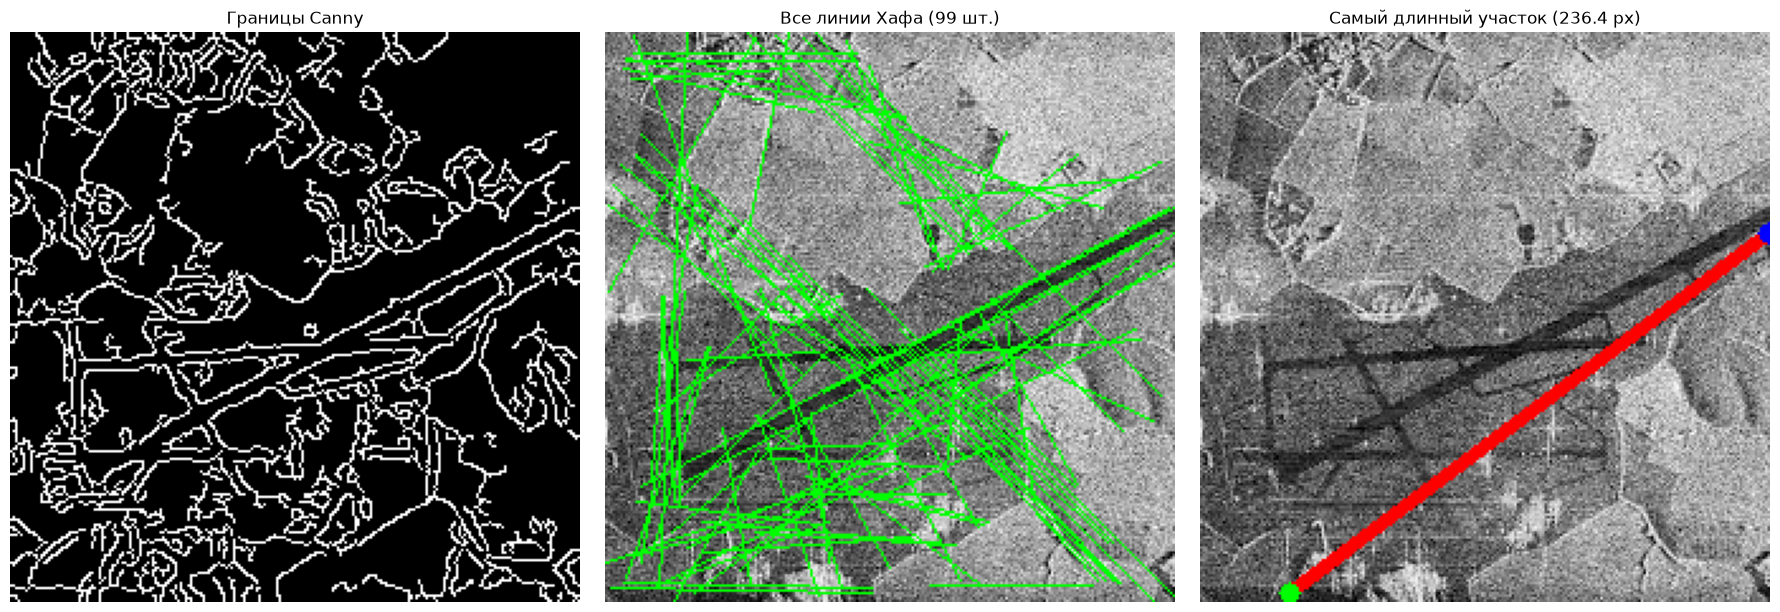

In [23]:
# Загрузка изображения sar_3.jpg
image_sar3 = cv2.imread('sar_3.jpg')
image_sar3_rgb = cv2.cvtColor(image_sar3, cv2.COLOR_BGR2RGB)
image_sar3_gray = cv2.cvtColor(image_sar3, cv2.COLOR_BGR2GRAY)

# Сглаживание шума Гауссом
blur_sar3 = cv2.GaussianBlur(image_sar3_gray, (5, 5), 1.5)

# Поиск границ Canny
edges_sar3 = cv2.Canny(blur_sar3, 40, 120, apertureSize=3)

# Поиск отрезков через Хафа
lines_p = cv2.HoughLinesP(
    edges_sar3, 
    rho=1, 
    theta=np.pi / 180, 
    threshold=40, 
    minLineLength=50, 
    maxLineGap=15
)

# Поиск самого длинного отрезка
img_all_lines = image_sar3_rgb.copy()
img_longest = image_sar3_rgb.copy()

longest_segment = None
max_length = 0.0

if lines_p is not None:
    for line in lines_p:
        x1, y1, x2, y2 = line[0] if len(line.shape) > 1 else line
        # Длина отрезка
        length = float(np.hypot(x2 - x1, y2 - y1))
        if length > max_length:
            max_length = length
            longest_segment = (int(x1), int(y1), int(x2), int(y2))
        # Отрисовка всех линий зеленым
        cv2.line(img_all_lines, (x1, y1), (x2, y2), (0, 255, 0), 1)

# Отрисовка самого длинного отрезка красным
if longest_segment is not None:
    x1, y1, x2, y2 = longest_segment
    cv2.line(img_longest, (x1, y1), (x2, y2), (255, 0, 0), 3)
    cv2.circle(img_longest, (x1, y1), 4, (0, 255, 0), -1)
    cv2.circle(img_longest, (x2, y2), 4, (0, 0, 255), -1)

print(f"Найдено линий: {len(lines_p) if lines_p is not None else 0}")
print(f"Самый длинный участок: от ({longest_segment[0]}, {longest_segment[1]}) до ({longest_segment[2]}, {longest_segment[3]})")
print(f"Длина участка: {max_length:.1f} px")

# Вывод картинок
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(edges_sar3, cmap='gray')
axes[0].set_title('Границы Canny', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img_all_lines)
axes[1].set_title(f'Все линии Хафа ({len(lines_p) if lines_p is not None else 0} шт.)', fontsize=12)
axes[1].axis('off')

axes[2].imshow(img_longest)
axes[2].set_title(f'Самый длинный участок ({max_length:.1f} px)', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

- Снимок зернистый и шумный. Если не сгладить его фильтром Гаусса, Canny найдет слишком много лишнего шума.
- Преобразование Хафа нашло границы взлетных полос аэродрома.
- Самый протяженный участок идет по диагонали через весь кадр, его длина — 236.4 px.

## Задание 2. Исследование бинаризации и выделение полосы дороги

Ручной порог: T = 95
Порог Отсу: T = 128.0
Итерационный порог: T = 127.5


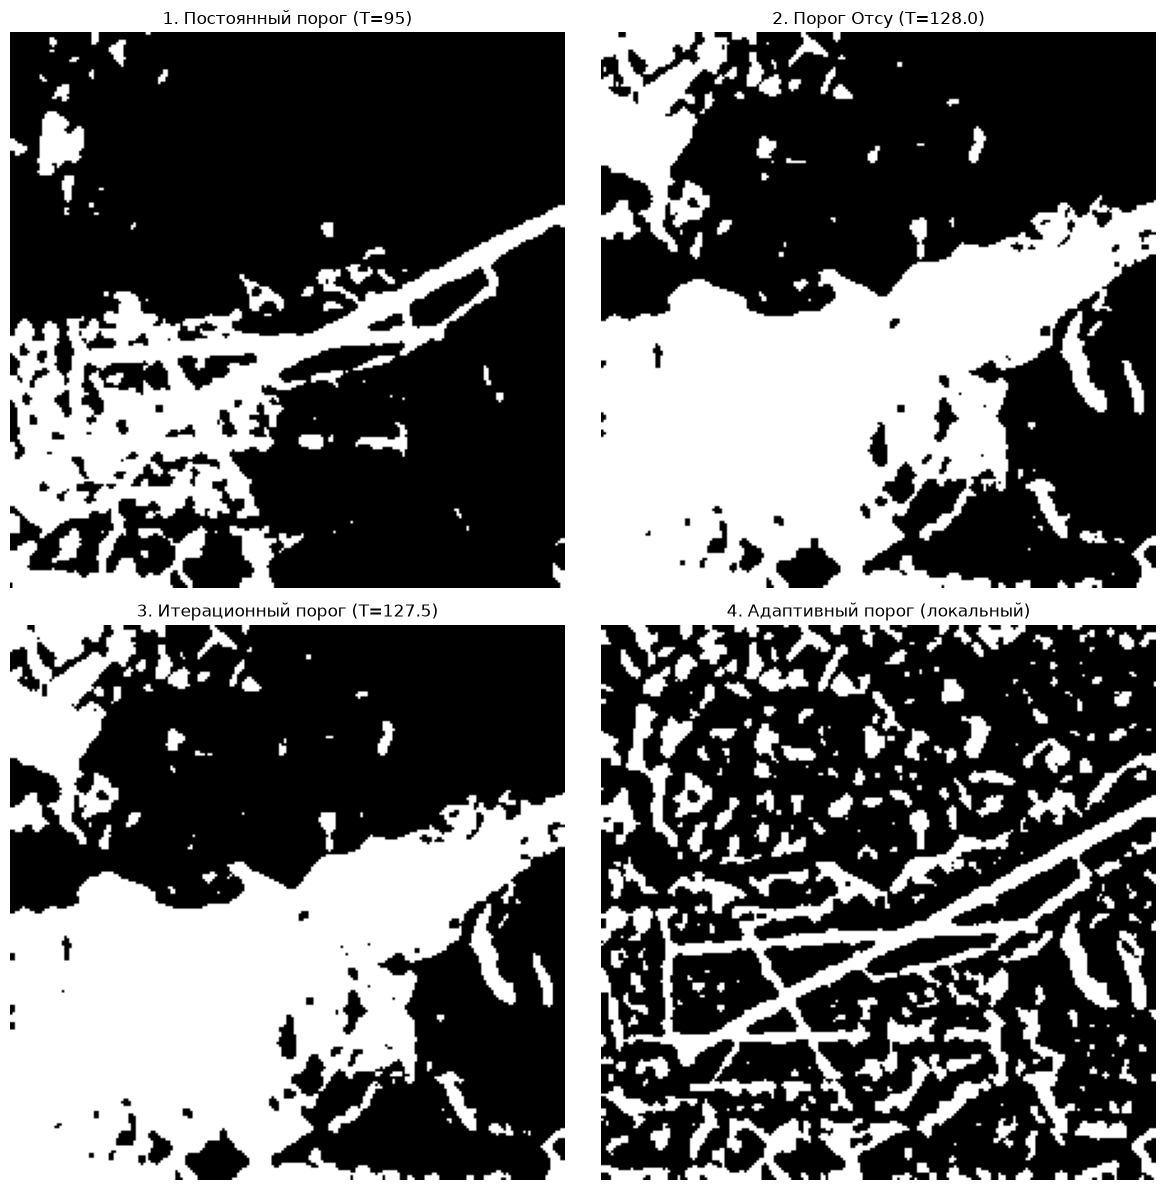

In [ ]:
# 1. Постоянный порог
T_fixed = 95
_, bin_fixed = cv2.threshold(blur_sar3, T_fixed, 255, cv2.THRESH_BINARY_INV)

# 2. Порог Отсу (автоматический)
T_otsu, bin_otsu = cv2.threshold(blur_sar3, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Итерационный порог
T_curr = (float(blur_sar3.min()) + float(blur_sar3.max())) / 2.0
while True:
    g1 = blur_sar3[blur_sar3 < T_curr]
    g2 = blur_sar3[blur_sar3 >= T_curr]
    m1 = g1.mean() if len(g1) > 0 else T_curr
    m2 = g2.mean() if len(g2) > 0 else T_curr
    T_next = (m1 + m2) / 2.0
    if abs(T_next - T_curr) < 0.5:
        break
    T_curr = T_next
T_iter = T_curr
_, bin_iter = cv2.threshold(blur_sar3, int(round(T_iter)), 255, cv2.THRESH_BINARY_INV)

# 4. Адаптивный порог
bin_adapt = cv2.adaptiveThreshold(
    blur_sar3, 
    255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY_INV, 
    31, 
    7
)

print(f"Ручной порог: T = {T_fixed}")
print(f"Порог Отсу: T = {T_otsu:.1f}")
print(f"Итерационный порог: T = {T_iter:.1f}")

# Сравнение способов бинаризации
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0, 0].imshow(bin_fixed, cmap='gray')
axes[0, 0].set_title(f'1. Постоянный порог (T={T_fixed})', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(bin_otsu, cmap='gray')
axes[0, 1].set_title(f'2. Порог Отсу (T={T_otsu:.1f})', fontsize=12)
axes[0, 1].axis('off')

axes[1, 0].imshow(bin_iter, cmap='gray')
axes[1, 0].set_title(f'3. Итерационный порог (T={T_iter:.1f})', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(bin_adapt, cmap='gray')
axes[1, 1].set_title('4. Адаптивный порог (локальный)', fontsize=12)
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

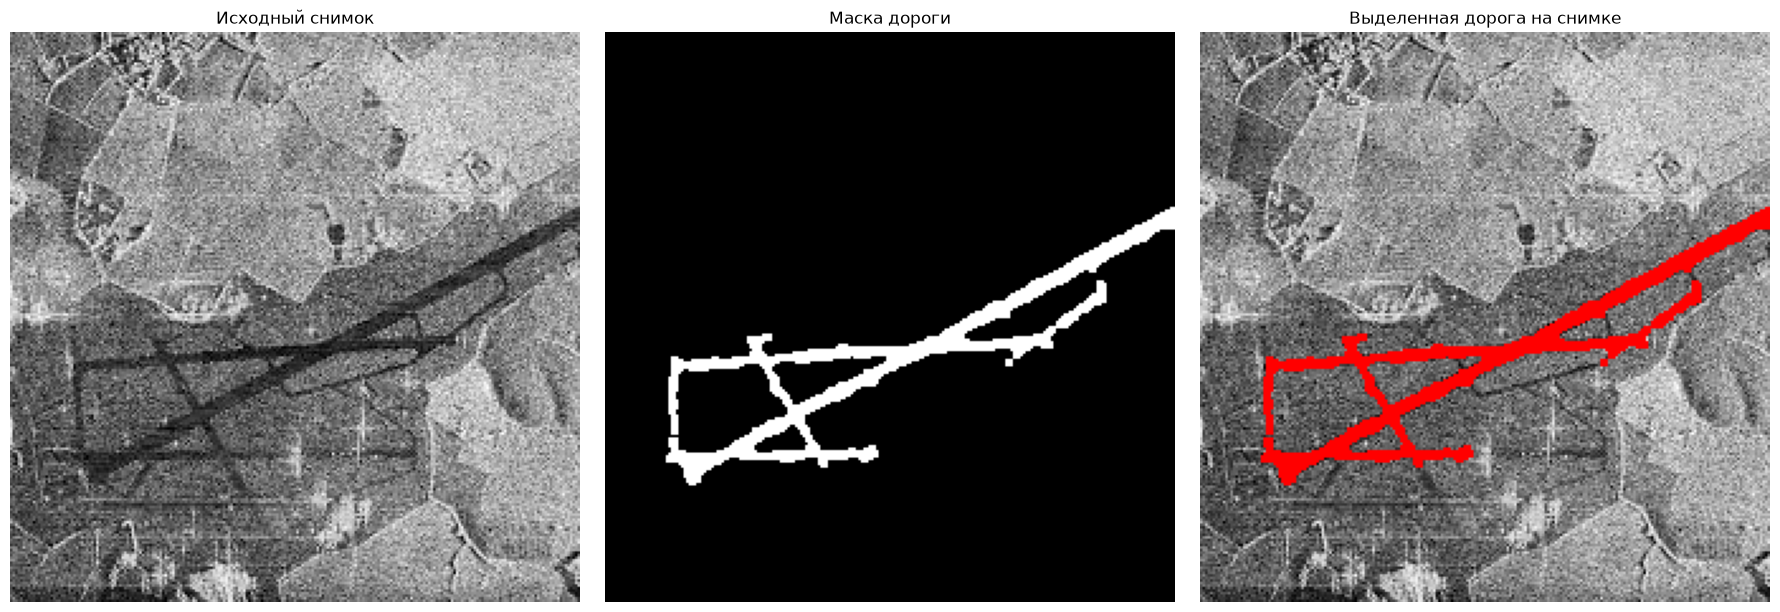

In [25]:
# Выделение полосы дороги

# Очистка от мелкого шума
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
bin_clean = cv2.morphologyEx(bin_adapt, cv2.MORPH_OPEN, kernel)

# Поиск отдельных объектов
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(bin_clean)

# Выбор самого длинного объекта (дороги)
road_mask = np.zeros_like(bin_clean)
for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    diagonal = np.hypot(w, h)
    # Фильтр по размеру и длине
    if diagonal > 60 and area > 100:
        road_mask[labels == i] = 255

# Наложение дороги на исходный снимок красным цветом
road_overlay = image_sar3_rgb.copy()
road_overlay[road_mask == 255] = [255, 0, 0]

# Вывод результата
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_sar3_rgb)
axes[0].set_title('Исходный снимок', fontsize=12)
axes[0].axis('off')

axes[1].imshow(road_mask, cmap='gray')
axes[1].set_title('Маска дороги', fontsize=12)
axes[1].axis('off')

axes[2].imshow(road_overlay)
axes[2].set_title('Выделенная дорога на снимке', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

1. **Постоянный порог:** требует ручного подбора под каждую картинку. При T=95 дорогу видно, но по углам остается лишний шум.
2. **Отсу и итерационный метод:** дали почти одинаковый порог (около 128). Они берут среднее по всей картинке сразу, поэтому вместе с полосой захватывают и темную землю вокруг.
3. **Адаптивный порог:** подошел лучше всего, так как считает порог кусочками (локально) и четко находит именно линии полосы.
4. **Выделение дороги:** после адаптивного порога убрали мелкие точки и оставили самый длинный связный объект — дорогу.